# Data check

This notebook describes the xView2 challenge training set before any score is computed. It counts what is in the data and shows what the images and polygons look like, to aid later choices in the preprocessing and the scores.

It covers the damage classes of each event and its disaster type, how many buildings fall into each damage class, how the pre- and post-event images differ in the conditions they were taken under, how large the buildings are, and what some example pairs look like with their polygons drawn on.


## Damage counts per event

Each post-event label file lists the buildings in one image pair with their damage class. The table counts the buildings in each class for every event, with the disaster type taken from the label metadata.

In [43]:
import os
import json
import pandas as pd

LABELS = "../../Dataset/train/labels/"
files = os.listdir(LABELS)

damage = {}
types = {}
for f in files:
    if "post" in f:
        event = f.split("_")[0]
        with open("../../Dataset/train/labels/" + f) as fh:
            data = json.load(fh)
        types[event] = data["metadata"]["disaster_type"]
        for b in data["features"]["xy"]:
            label = b["properties"]["subtype"]
            damage.setdefault(event, {})
            damage[event][label] = damage[event].get(label, 0) + 1

table = pd.DataFrame(damage).T.fillna(0).astype(int)
table["total"] = table.sum(axis=1)
table.insert(0, "disaster_type", pd.Series(types))
table


,disaster_type,no-damage,minor-damage,destroyed,major-damage,un-classified,total
guatemala-volcano,volcano,639,9,25,9,174,856
hurricane-florence,flooding,4689,132,54,1245,326,6446
hurricane-harvey,flooding,11423,2663,401,8238,289,23014
hurricane-matthew,wind,2515,6548,2147,1945,784,13939
hurricane-michael,wind,14588,5207,757,1902,232,22686
mexico-earthquake,earthquake,32066,110,2,18,75,32271
midwest-flooding,flooding,8128,149,75,119,285,8756
palu-tsunami,tsunami,25455,1,4966,571,401,31394
santa-rosa-wildfire,fire,9285,78,3471,63,53,12950
socal-fire,fire,8638,83,1329,51,374,10475


Undamaged buildings dominate every event. Mexico City is the most extreme case, with over 32,000 undamaged buildings and only 2 destroyed, while Palu has almost 5,000 destroyed buildings. It is also worth noting the disaster types also show that Hurricane Florence and Hurricane Harvey are labeled as flooding rather than wind.

The charts below compare undamaged and damaged buildings, where damaged means minor, major, or destroyed. The linear scale shows the true proportions, and the log scale keeps the smaller counts visible.

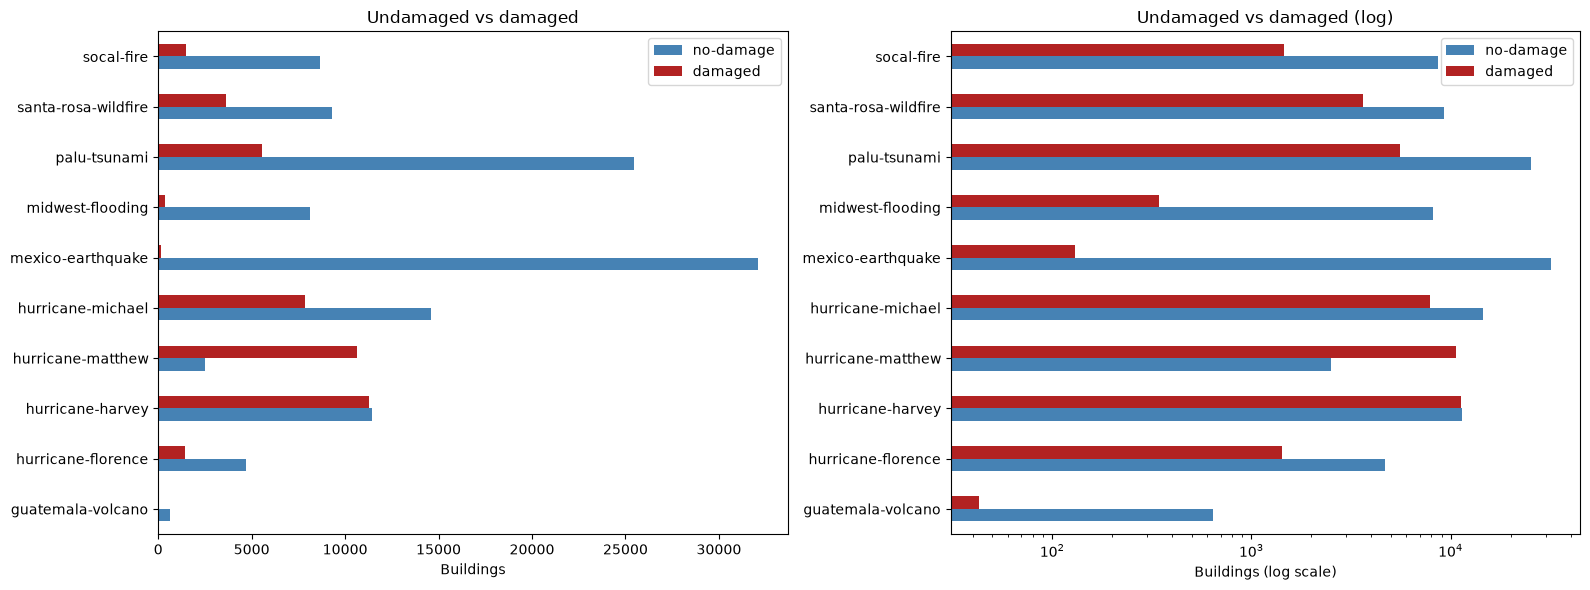

In [61]:
import matplotlib.pyplot as plt

table["damaged"] = table[["minor-damage", "major-damage", "destroyed"]].sum(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, log in zip(axes, [False, True]):
    table[["no-damage", "damaged"]].plot.barh(
        ax=ax, logx=log, color=["steelblue", "firebrick"])
    ax.set_xlabel("Buildings (log scale)" if log else "Buildings")
    ax.set_title("Undamaged vs damaged" + (" (log)" if log else ""))
plt.tight_layout()
plt.show()

The damaged buildings are then split into minor, major, and destroyed.

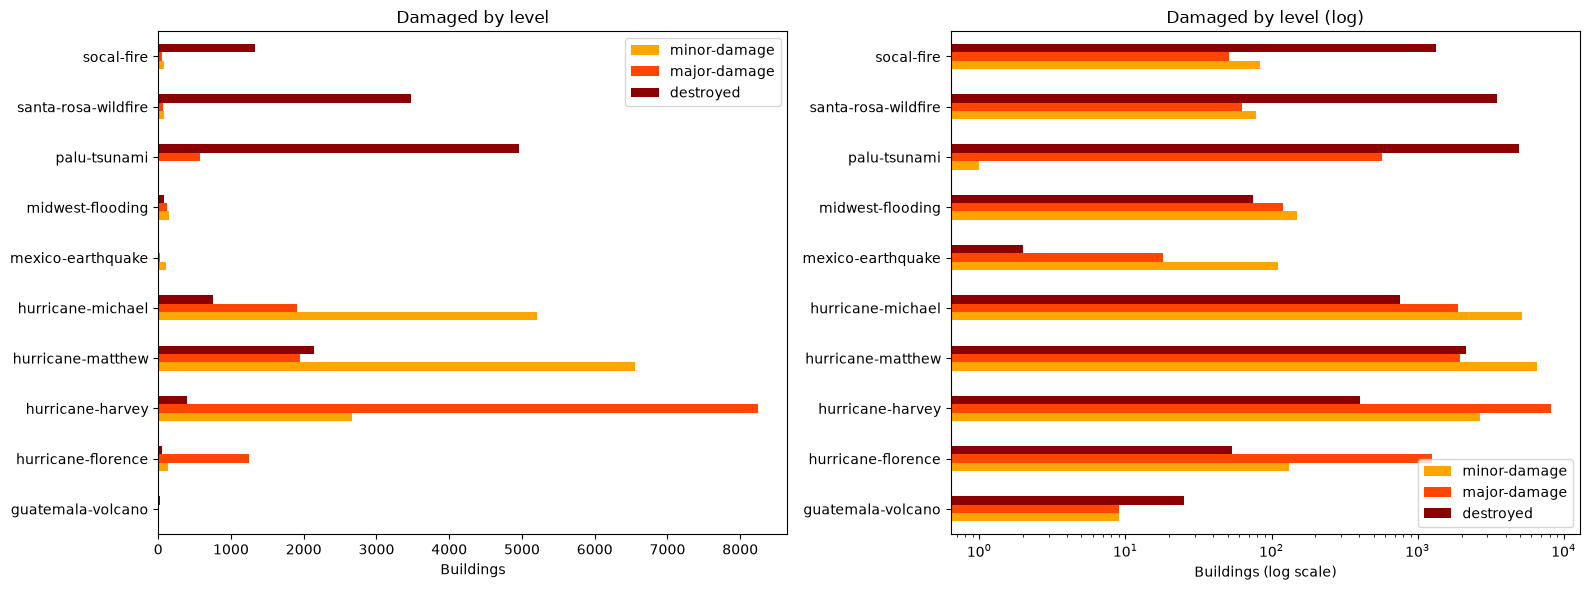

In [62]:
cols = ["minor-damage", "major-damage", "destroyed"]
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, log in zip(axes, [False, True]):
    table[cols].plot.barh(
        ax=ax, logx=log, color=["orange", "orangered", "darkred"])
    ax.set_xlabel("Buildings (log scale)" if log else "Buildings")
    ax.set_title("Damaged by level" + (" (log)" if log else ""))
plt.tight_layout()
plt.show()

Most destroyed buildings in the practice events come from the two fires, while Mexico City has almost none. Florence and Harvey are mostly major damage, and the hurricanes contain most of the minor damage.

## Pre- and post-event image conditions

The two images in a pair were taken on different dates. Differences in viewing angle, pixel size, and sun elevation change how an intact building appears, through shifted roofs, scale changes, and different shadows. Each chart overlays the pre- and post-event values of one of these settings across all image pairs.

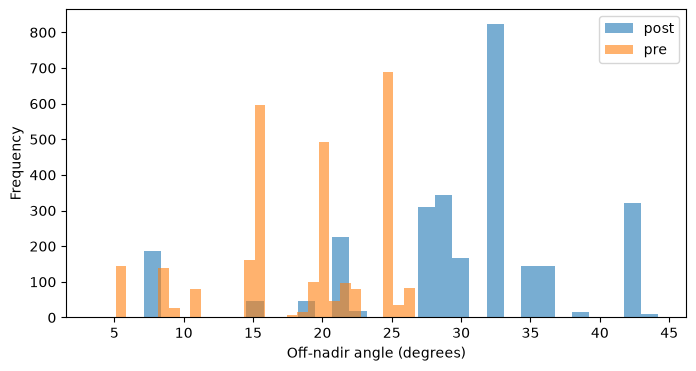

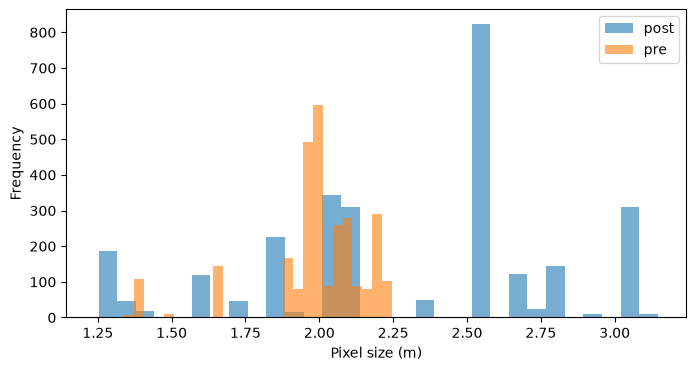

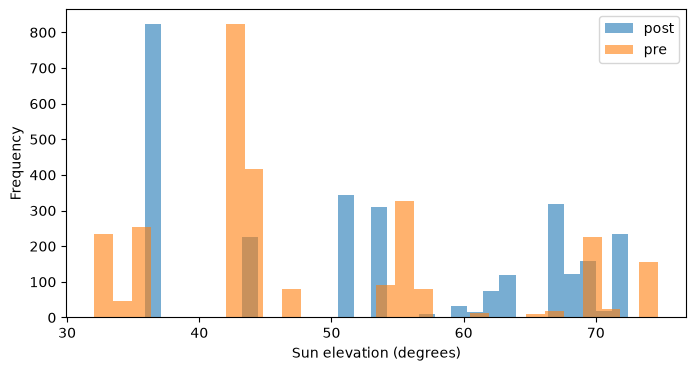

In [53]:
rows = []
for f in files:
    with open("../../Dataset/train/labels/" + f) as fh:
        m = json.load(fh)["metadata"]
    rows.append({"when": "pre" if "pre" in f else "post",
                 "Off-nadir angle (degrees)": m["off_nadir_angle"],
                 "Pixel size (m)": m["gsd"],
                 "Sun elevation (degrees)": m["sun_elevation"]})
meta = pd.DataFrame(rows)

for col in meta.columns[1:]:
    ax = meta.groupby("when")[col].plot.hist(bins=30, alpha=0.6, legend=True, figsize=(8, 4))
    plt.xlabel(col)
    plt.show()

It can be observed that viewing angle, pixel size, and sun elevation all change between the pre- and post-event images, and the changes follow no consistent pattern across pairs. This is why the images are preprocessed before they are compared.

## Building sizes

Building size matters for the later steps, since small polygons leave few pixels for a score and are harder to align. The histogram shows the area of every building polygon in pixels, on a log scale because sizes range from tens to tens of thousands of pixels.

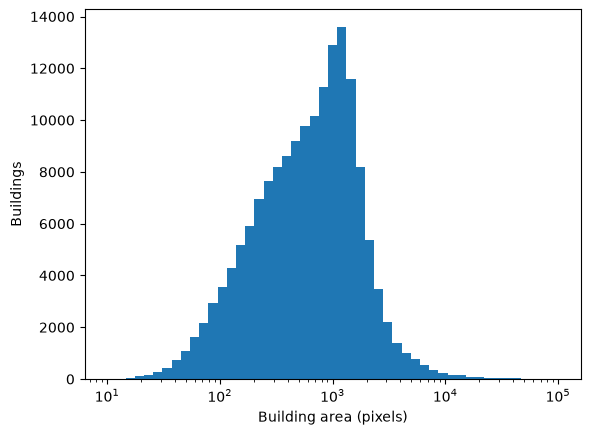

In [55]:
import numpy as np
import cv2

areas = []
for f in files:
    if "post" in f:
        for b in json.load(open(LABELS + f))["features"]["xy"]:
            pts = b["wkt"][10:-2].split(", ")
            areas.append(cv2.contourArea(np.array([p.split() for p in pts], np.float32)))

plt.hist(areas, bins=np.logspace(1, 5, 50))
plt.xscale("log")
plt.xlabel("Building area (pixels)")
plt.ylabel("Buildings")
plt.show()

Most buildings cover between about 100 and 3,000 pixels, with a peak near 1,000. Very small buildings, under about 30 pixels, are rare, and a small number of large buildings exceed 10,000 pixels.

## Example image pairs

The following figures show image pairs with their building polygons drawn on top, colored by damage class: cyan for no damage, yellow for minor, orange for major, and red for destroyed. The polygons come from the post-event labels and are drawn on both images.

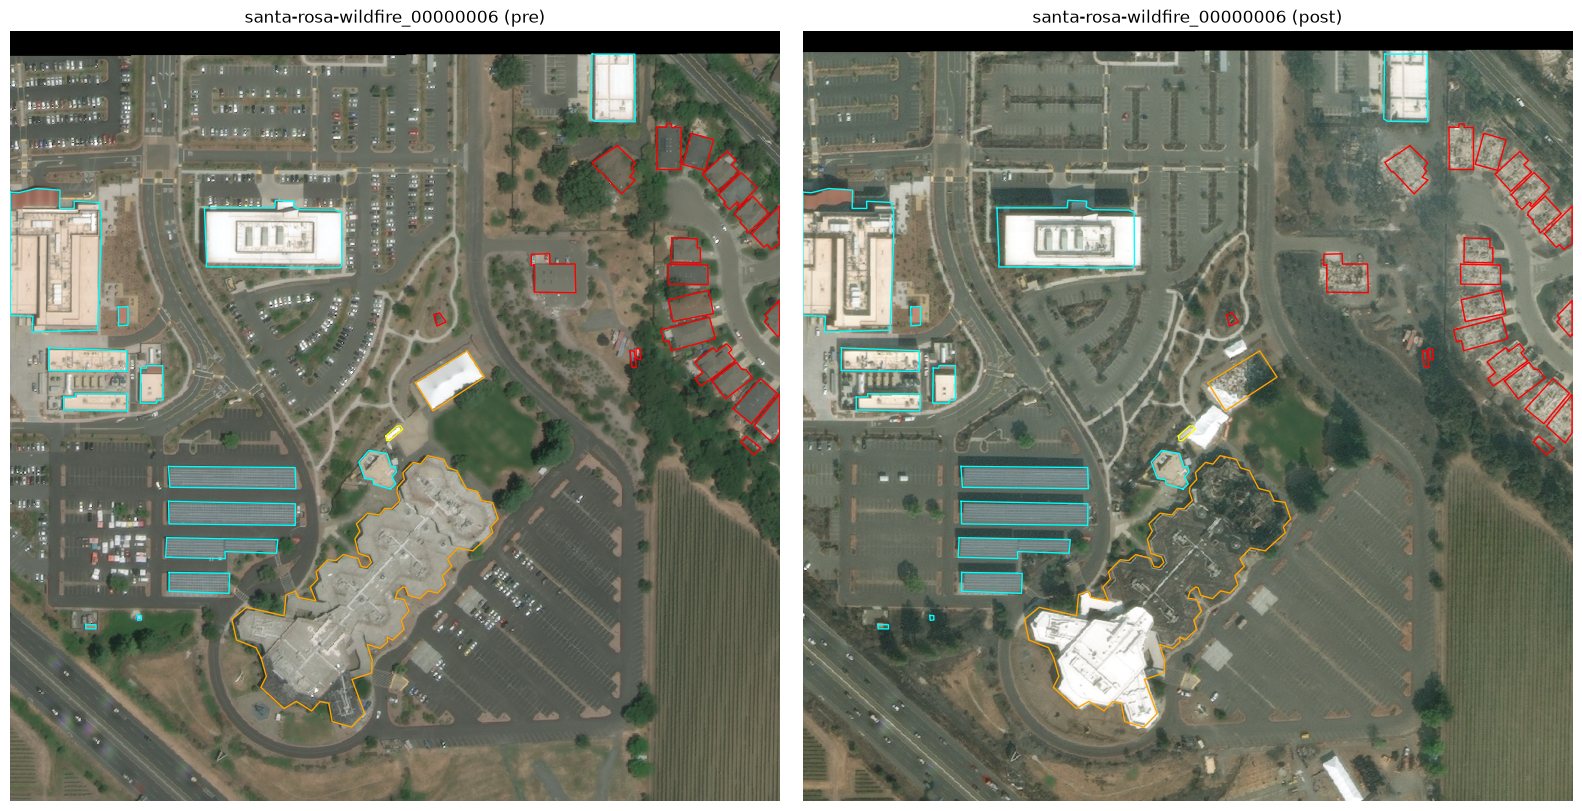

In [59]:
IMAGES = "../../Dataset/train/images/"
colors = {"no-damage": "cyan", "minor-damage": "yellow",
          "major-damage": "orange", "destroyed": "red", "un-classified": "white"}

def show_pair(pair):
    buildings = json.load(open(f"{LABELS}{pair}_post_disaster.json"))["features"]["xy"]
    fig, axes = plt.subplots(1, 2, figsize=(16, 8))
    for ax, when in zip(axes, ["pre", "post"]):
        img = cv2.imread(f"{IMAGES}{pair}_{when}_disaster.png")[:, :, ::-1]
        ax.imshow(img)
        for b in buildings:
            pts = np.array([p.split() for p in b["wkt"][10:-2].split(", ")], float)
            ax.plot(pts[:, 0], pts[:, 1], color=colors[b["properties"]["subtype"]], linewidth=1)
        ax.set_title(f"{pair} ({when})")
        ax.axis("off")
    plt.tight_layout()
    plt.show()

show_pair("santa-rosa-wildfire_00000006")

In this Santa Rosa pair above, the destroyed houses on the right have burned down to ash and foundations, which makes the change clear. The large building marked as major damage burned only in part, yet the whole polygon carries one label. The post-event image is also hazier overall, so even intact buildings look slightly different.


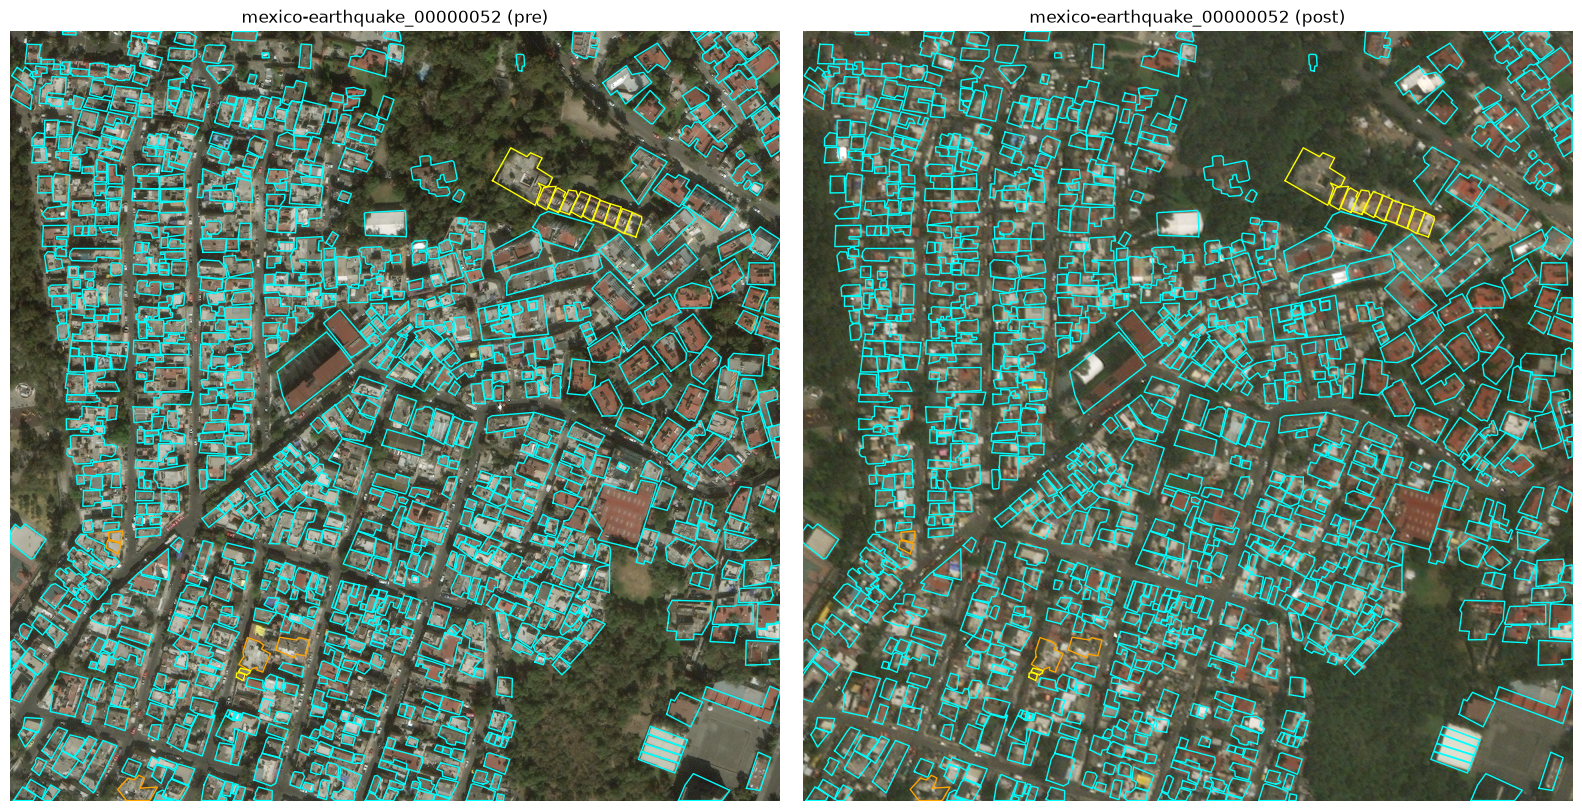

In [60]:
show_pair("mexico-earthquake_00000052")

In this Mexico City pair, the damage is hard to see. The few buildings marked as minor or major look almost the same in both images. The area is also dense, with many small buildings whose polygons touch.

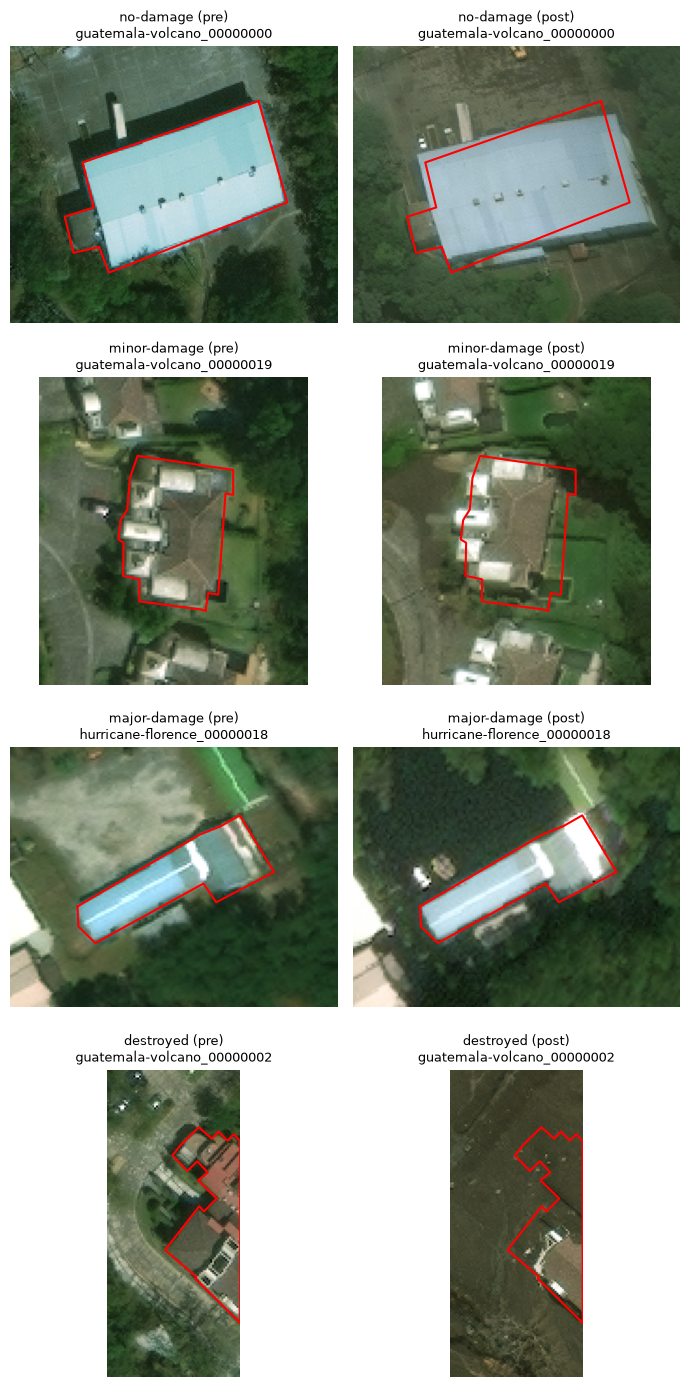

In [58]:
classes = ["no-damage", "minor-damage", "major-damage", "destroyed"]
examples = {}
for f in files:
    if "post" in f and len(examples) < 4:
        for b in json.load(open(LABELS + f))["features"]["xy"]:
            c = b["properties"]["subtype"]
            pts = np.array([p.split() for p in b["wkt"][10:-2].split(", ")], np.float32)
            if c in classes and c not in examples and cv2.contourArea(pts) > 1500:
                examples[c] = (f.rsplit("_", 2)[0], pts)

fig, axes = plt.subplots(4, 2, figsize=(7, 14))
for row, c in enumerate(classes):
    pair, pts = examples[c]
    x0, y0 = (pts.min(axis=0) - 30).clip(0).astype(int)
    x1, y1 = (pts.max(axis=0) + 30).astype(int)
    for col, when in enumerate(["pre", "post"]):
        img = cv2.imread(f"{IMAGES}{pair}_{when}_disaster.png")[:, :, ::-1]
        ax = axes[row, col]
        ax.imshow(img[y0:y1, x0:x1])
        ax.plot(pts[:, 0] - x0, pts[:, 1] - y0, color="red", linewidth=1.5)
        ax.set_title(f"{c} ({when})\n{pair}", fontsize=9)
        ax.axis("off")
plt.tight_layout()
plt.show()

The close-ups show one building from each damage class. The destroyed building is clearly buried under ash, while the minor and major examples look almost unchanged from above; the major one is a flooded building whose roof is intact. The undamaged building appears shifted between the two dates, which could be mistaken for change.

## Summary

- The training set contains 10 events. Florence and Harvey are labeled as flooding, and Palu as a tsunami.
- Undamaged buildings dominate every event. Mexico City has only 2 destroyed buildings, and most destroyed buildings in the practice events come from the two fires.
- Viewing angle, pixel size, and sun elevation change between the pre- and post-event images with no consistent pattern, so the images need preprocessing before comparison.
- Most buildings cover between about 100 and 3,000 pixels.
- Destroyed buildings are clearly visible, while minor and major damage often look unchanged from above.